# Notebook 04 — Model Evaluation
## American Sign Language (ASL) Detection
---
Loads the trained model, runs it on the held-out test set, and produces:
- Overall accuracy
- Confusion matrix
- Per-class classification report (precision, recall, F1)

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from tensorflow.keras.models import load_model
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
# Load the best saved model and test data
model = load_model('models/best_lstm_model.keras')
print('Model loaded.')
model.summary()

X_test = np.load('processed_data/X_test.npy')
y_test = np.load('processed_data/y_test.npy')

with open('processed_data/class_names.json') as f:
    class_names = json.load(f)
with open('models/model_metadata.json') as f:
    meta = json.load(f)

NUM_CLASSES = len(class_names)
y_test_cat  = to_categorical(y_test, NUM_CLASSES)

print(f'\nTest set : {X_test.shape}')
print(f'Classes  : {NUM_CLASSES}')
print(f'Best val accuracy (from training): {meta["best_val_accuracy"]:.4f}')

Model loaded.


Model: "ASL_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 30, 256)        │       261,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,340,636 (5.11 MB)

 Trainable params: 446,622 (1.70 MB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 893,246 (3.41 MB)


Test set : (150, 30, 126)
Classes  : 30
Best val accuracy (from training): 0.7600


In [3]:
# Generate predictions on the test set
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test, y_pred)
correct   = (y_pred == y_test).sum()
incorrect = (y_pred != y_test).sum()

print(f'Test Accuracy : {acc:.4f}  ({acc*100:.2f}%)')
print(f'Correct       : {correct} / {len(y_test)}')
print(f'Incorrect     : {incorrect} / {len(y_test)}')

Test Accuracy : 0.7133  (71.33%)
Correct       : 107 / 150
Incorrect     : 43 / 150


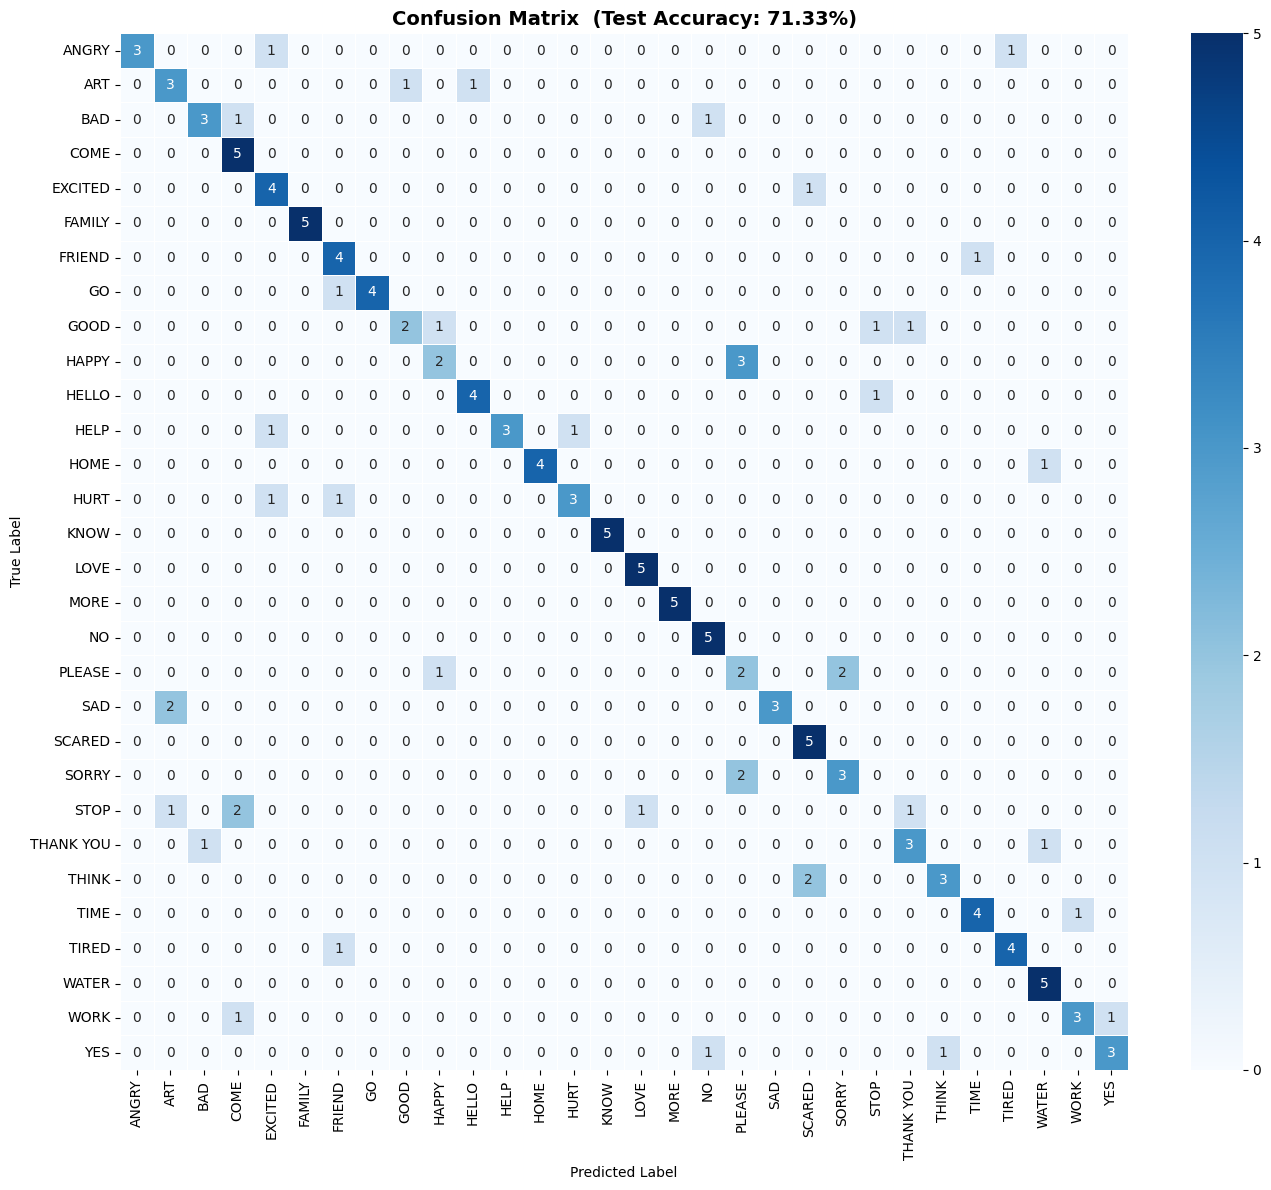

In [4]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5)
plt.title(f'Confusion Matrix  (Test Accuracy: {acc*100:.2f}%)',
          fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('processed_data/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Classification Report:
              precision    recall  f1-score   support

       ANGRY       1.00      0.60      0.75         5
         ART       0.50      0.60      0.55         5
         BAD       0.75      0.60      0.67         5
        COME       0.56      1.00      0.71         5
     EXCITED       0.57      0.80      0.67         5
      FAMILY       1.00      1.00      1.00         5
      FRIEND       0.57      0.80      0.67         5
          GO       1.00      0.80      0.89         5
        GOOD       0.67      0.40      0.50         5
       HAPPY       0.50      0.40      0.44         5
       HELLO       0.80      0.80      0.80         5
        HELP       1.00      0.60      0.75         5
        HOME       1.00      0.80      0.89         5
        HURT       0.75      0.60      0.67         5
        KNOW       1.00      1.00      1.00         5
        LOVE       0.83      1.00      0.91         5
        MORE       1.00      1.00      1.00         5
    

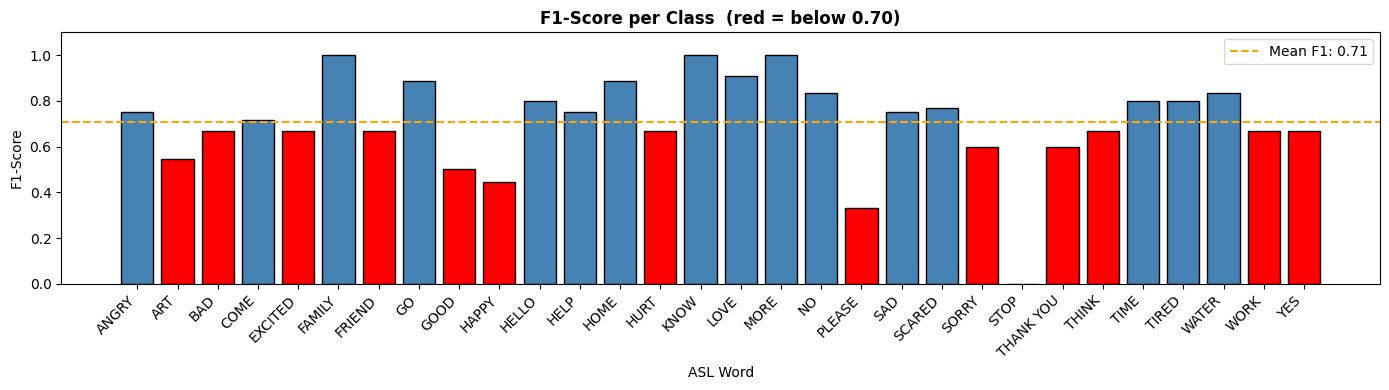

Best class : FAMILY  (F1=1.000)
Worst class: STOP  (F1=0.000)


In [5]:
# Full classification report
print('Classification Report:')
print('=' * 70)
print(classification_report(y_test, y_pred, target_names=class_names))

# Per-class F1 bar chart
from sklearn.metrics import f1_score
f1_scores = f1_score(y_test, y_pred, average=None)

colors = ['red' if s < 0.7 else 'steelblue' for s in f1_scores]
plt.figure(figsize=(14, 4))
plt.bar(class_names, f1_scores, color=colors, edgecolor='black')
plt.axhline(f1_scores.mean(), color='orange', linestyle='--',
            label=f'Mean F1: {f1_scores.mean():.2f}')
plt.title('F1-Score per Class  (red = below 0.70)', fontweight='bold')
plt.xlabel('ASL Word')
plt.ylabel('F1-Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig('processed_data/per_class_f1.png', dpi=150)
plt.show()

print(f'Best class : {class_names[f1_scores.argmax()]}  (F1={f1_scores.max():.3f})')
print(f'Worst class: {class_names[f1_scores.argmin()]}  (F1={f1_scores.min():.3f})')

In [6]:
# Save confidence threshold to metadata and print summary
with open('models/model_metadata.json') as f:
    meta = json.load(f)
meta['confidence_threshold'] = 0.7
with open('models/model_metadata.json', 'w') as f:
    json.dump(meta, f, indent=2)

print('=' * 50)
print('  EVALUATION SUMMARY')
print('=' * 50)
print(f'  Test Accuracy  : {acc:.4f} ({acc*100:.2f}%)')
print(f'  Mean F1-Score  : {f1_scores.mean():.4f}')
print(f'  Samples tested : {len(y_test)}')
print(f'  Confidence thr : 0.7 (saved to metadata)')
print('=' * 50)
print('\nProceed to Notebook 05.')

  EVALUATION SUMMARY
  Test Accuracy  : 0.7133 (71.33%)
  Mean F1-Score  : 0.7059
  Samples tested : 150
  Confidence thr : 0.7 (saved to metadata)

Proceed to Notebook 05.
